In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/competitions/comment-category-prediction-challenge/Sample.csv
/kaggle/input/competitions/comment-category-prediction-challenge/train.csv
/kaggle/input/competitions/comment-category-prediction-challenge/test.csv


✅ Imports done (sklearn + lightgbm, no NLTK)
✅ Train: (197999, 15) | Test: (102000, 14)
⏳ Cleaning text...
✅ Done in 17.7s
✅ Toxicity features created
✅ All features. Train: (197999, 37) | Test: (102000, 36)
⏳ Word TF-IDF (35K, trigrams, no stop_words)...
✅ Word: 35000 in 97.9s
⏳ Char TF-IDF (25K)...
✅ Char: 25000 in 135.2s
✅ One-hot demographics: 19 features
   Categories: ['race_black' 'race_latino' 'race_missing' 'race_none' 'race_other'
 'race_white' 'religion_buddhist' 'religion_christian' 'religion_hindu'
 'religion_jewish' 'religion_missing' 'religion_muslim' 'religion_none'
 'religion_other' 'gender_male' 'gender_missing' 'gender_none'
 'gender_other' 'gender_transgender']

✅ Total features: 60048
   Word TF-IDF: 35000
   Char TF-IDF: 25000
   One-hot demographics: 19
   Numeric: 21 (incl 7 NEW toxicity)
   Binary: 8 (incl 3 NEW demographic flags)
✅ Train: 158,399 | Val: 39,600
⏳ LinearSVC (custom weights)...

  LinearSVC (custom): Acc=0.9120 | Macro F1=0.8226 | Wt F1=0.9129
  

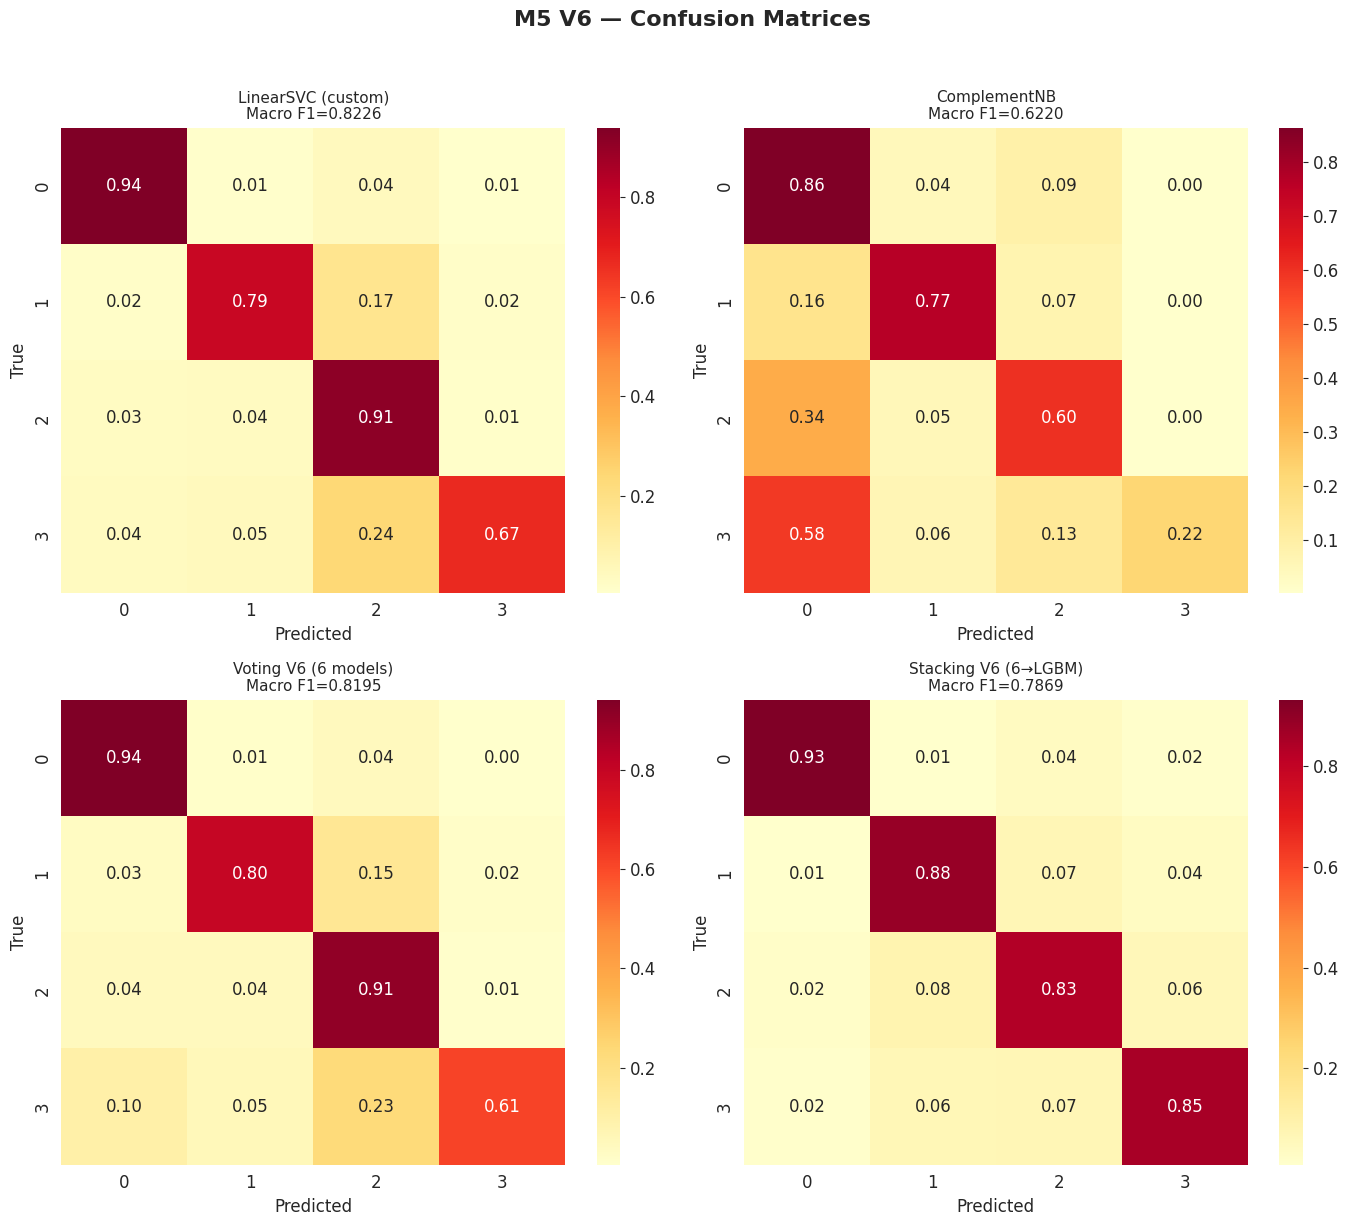


🏆 Retraining top models on ALL data...
⏳ LinearSVC...
⏳ Stacking V6 (6→LGBM)...


TerminatedWorkerError: A worker process managed by the executor was unexpectedly terminated. This could be caused by a segmentation fault while calling the function or by an excessive memory usage causing the Operating System to kill the worker.

The exit codes of the workers are {SIGKILL(-9)}
Detailed tracebacks of the workers should have been printed to stderr in the executor process if faulthandler was not disabled.

In [2]:
# %% [markdown]
# # 🏆 Milestone 5 V6: Maximum Diversity Pipeline
#
# **V6 = V5 base + all untried high-potential techniques:**
#
# | NEW in V6 | Why |
# | --- | --- |
# | ComplementNB as stacking base | Designed for imbalanced text, MASSIVE diversity |
# | RidgeClassifier as stacking base | Different regularization (L2 only) |
# | LightGBM as meta-learner | Non-linear stacking instead of LR |
# | Toxicity features (caps, profanity) | Direct signal TF-IDF misses |
# | One-hot demographics | race/religion/gender interactions |
# | Individual demographic flags | has_race, has_religion, has_gender |
#
# **Allowed libraries only:** sklearn, lightgbm, numpy, pandas, scipy, re, matplotlib, seaborn

# %%
import numpy as np
import pandas as pd
import re
import time
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import (LogisticRegression, SGDClassifier,
                                  PassiveAggressiveClassifier, RidgeClassifier)
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB, MultinomialNB
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import VotingClassifier, StackingClassifier
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix)
from scipy.sparse import hstack, csr_matrix

import lightgbm as lgb

import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 12
sns.set_style("whitegrid")
sns.set_palette("viridis")

print("✅ Imports done (sklearn + lightgbm, no NLTK)")

def sparse_abs(X):
    """Copy sparse matrix then apply abs — avoids joblib read-only error."""
    X_copy = X.copy()
    X_copy.data = np.abs(X_copy.data)
    return X_copy

# %% [markdown]
# NOTE: M5 Questions already answered in milestone_5_final_push.py

# %%
train = pd.read_csv("/kaggle/input/competitions/comment-category-prediction-challenge/train.csv")
test = pd.read_csv("/kaggle/input/competitions/comment-category-prediction-challenge/test.csv")
sample = pd.read_csv("/kaggle/input/competitions/comment-category-prediction-challenge/Sample.csv")

train = train.dropna(subset=["comment"])
print(f"✅ Train: {train.shape} | Test: {test.shape}")

# %% [markdown]
# ## 1. Text Cleaning (Minimal — no stemming)

# %%
def clean_text(text):
    """Minimal cleaning — no stemming (proven: stemming hurts or adds nothing)."""
    if not isinstance(text, str):
        return ""
    text = text.lower()
    text = re.sub(r'http\S+|www\.\S+', ' ', text)
    text = re.sub(r'<[^>]+>', ' ', text)
    text = re.sub(r'\S+@\S+', ' ', text)
    text = re.sub(r'\b\d+\b', ' ', text)
    text = re.sub(r"[^a-z\s']", ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

print("⏳ Cleaning text...")
t0 = time.time()
train["comment_clean"] = train["comment"].astype(str).apply(clean_text)
test["comment_clean"]  = test["comment"].astype(str).apply(clean_text)
print(f"✅ Done in {time.time()-t0:.1f}s")

# %% [markdown]
# ## 2. Feature Engineering (EXPANDED — V6 adds toxicity + demographics)

# %%
# ════════════════════════════════════════════════════════════
# TOXICITY SIGNAL FEATURES (NEW in V6)
# These capture patterns TF-IDF misses as explicit counts
# ════════════════════════════════════════════════════════════
TOXIC_WORDS = [
    "stupid", "idiot", "moron", "dumb", "hate", "kill", "die", "ugly",
    "loser", "fool", "shut", "crap", "suck", "worst", "pathetic",
    "disgusting", "horrible", "terrible", "ignorant", "racist",
    "bigot", "sexist", "trash", "garbage", "worthless", "creep",
    "liar", "hypocrite", "scum", "coward", "troll", "insane",
    "ridiculous", "absurd", "nonsense", "delusional", "incompetent"
]

for data in [train, test]:
    raw_comment = data["comment"].astype(str)

    # Caps ratio — "YOU ARE STUPID" vs "you are stupid"
    data["caps_ratio"] = raw_comment.apply(
        lambda x: sum(c.isupper() for c in x) / (len(x) + 1))

    # Exclamation & question marks — toxic comments shout
    data["excl_count"] = raw_comment.str.count("!")
    data["quest_count"] = raw_comment.str.count(r"\?")

    # Toxic word count — direct toxicity signal
    data["toxic_word_count"] = raw_comment.str.lower().apply(
        lambda x: sum(1 for w in x.split() if w in TOXIC_WORDS))

    # Repeated characters — "stuuuupid", "nooooo"
    data["repeated_chars"] = raw_comment.apply(
        lambda x: len(re.findall(r'(.)\1{2,}', x)))

    # Unique word ratio — low = repetitive rant
    data["unique_ratio"] = raw_comment.apply(
        lambda x: len(set(x.lower().split())) / (len(x.split()) + 1))

    # ALL CAPS word count — "YOU ARE AN IDIOT"
    data["allcaps_words"] = raw_comment.apply(
        lambda x: sum(1 for w in x.split() if w.isupper() and len(w) > 1))

print("✅ Toxicity features created")

# %%
# ════════════════════════════════════════════════════════════
# STANDARD + DEMOGRAPHIC FEATURES
# ════════════════════════════════════════════════════════════
for data in [train, test]:
    data["comment"] = data["comment"].fillna("")
    data["created_date"] = pd.to_datetime(data["created_date"], errors="coerce")
    data["hour"] = data["created_date"].dt.hour
    data["day_of_week"] = data["created_date"].dt.dayofweek
    data["month"] = data["created_date"].dt.month
    data["comment_length"] = data["comment"].astype(str).str.len()
    data["word_count"] = data["comment"].astype(str).str.split().str.len().fillna(0).astype(int)
    data["avg_word_length"] = data["comment_length"] / (data["word_count"] + 1)
    data["total_votes"] = data["upvote"] + data["downvote"]
    data["vote_diff"] = data["upvote"] - data["downvote"]
    data["vote_ratio"] = data["upvote"] / (data["downvote"] + 1)
    data["total_emoticons"] = data["emoticon_1"] + data["emoticon_2"] + data["emoticon_3"]

    # Individual demographic flags (NEW — V5 only had has_detection)
    for col in ["race", "religion", "gender"]:
        data[col] = data[col].fillna("missing")
        data[f"has_{col}"] = data[col].ne("missing").astype(int)

    data["has_detection"] = (data[["race","religion","gender"]].ne("missing").any(axis=1)).astype(int)

print(f"✅ All features. Train: {train.shape} | Test: {test.shape}")

# %% [markdown]
# ## 3. TF-IDF (35K word + 25K char = 60K)

# %%
print("⏳ Word TF-IDF (35K, trigrams, no stop_words)...")
t0 = time.time()
tfidf_word = TfidfVectorizer(
    max_features=35000, ngram_range=(1, 3),
    min_df=3, max_df=0.9, sublinear_tf=True
)
X_word_train = tfidf_word.fit_transform(train["comment_clean"])
X_word_test  = tfidf_word.transform(test["comment_clean"])
print(f"✅ Word: {X_word_train.shape[1]} in {time.time()-t0:.1f}s")

print("⏳ Char TF-IDF (25K)...")
t0 = time.time()
tfidf_char = TfidfVectorizer(
    analyzer="char_wb", ngram_range=(3, 5),
    max_features=25000, min_df=3, max_df=0.9, sublinear_tf=True
)
X_char_train = tfidf_char.fit_transform(train["comment_clean"])
X_char_test  = tfidf_char.transform(test["comment_clean"])
print(f"✅ Char: {X_char_train.shape[1]} in {time.time()-t0:.1f}s")

# %% [markdown]
# ## 4. One-Hot Encode Demographics (NEW in V6)

# %%
cat_cols = ["race", "religion", "gender"]
ohe = OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=True)
X_cat_train = ohe.fit_transform(train[cat_cols])
X_cat_test  = ohe.transform(test[cat_cols])
print(f"✅ One-hot demographics: {X_cat_train.shape[1]} features")
print(f"   Categories: {ohe.get_feature_names_out()}")

# %% [markdown]
# ## 5. Combine All Features

# %%
numeric_features = [
    "upvote", "downvote", "if_1", "if_2",
    "comment_length", "word_count", "avg_word_length",
    "total_votes", "vote_diff", "vote_ratio",
    "total_emoticons", "hour", "day_of_week", "month",
    # NEW toxicity features
    "caps_ratio", "excl_count", "quest_count",
    "toxic_word_count", "repeated_chars", "unique_ratio", "allcaps_words"
]
binary_features = [
    "emoticon_1", "emoticon_2", "emoticon_3", "disability",
    "has_detection", "has_race", "has_religion", "has_gender"  # NEW individual flags
]

X_num_train = train[numeric_features].values.copy()
X_bin_train = train[binary_features].values.astype(float)
X_num_test  = test[numeric_features].values.copy()
X_bin_test  = test[binary_features].values.astype(float)
y_all = train["label"].values

# Log transform skewed
skewed_cols = ["upvote", "downvote", "if_1", "if_2",
               "total_votes", "vote_ratio", "comment_length", "word_count",
               "excl_count", "quest_count", "toxic_word_count"]
for col in skewed_cols:
    idx = numeric_features.index(col)
    X_num_train[:, idx] = np.log1p(np.clip(X_num_train[:, idx], 0, None))
    X_num_test[:, idx]  = np.log1p(np.clip(X_num_test[:, idx], 0, None))

scaler = StandardScaler()
X_num_scaled_train = scaler.fit_transform(X_num_train)
X_num_scaled_test  = scaler.transform(X_num_test)

# Full matrix: TF-IDF + one-hot demographics + numeric + binary
X_all = hstack([X_word_train, X_char_train, X_cat_train,
                csr_matrix(X_num_scaled_train), csr_matrix(X_bin_train)])
X_test_all = hstack([X_word_test, X_char_test, X_cat_test,
                     csr_matrix(X_num_scaled_test), csr_matrix(X_bin_test)])

print(f"\n✅ Total features: {X_all.shape[1]}")
print(f"   Word TF-IDF: {X_word_train.shape[1]}")
print(f"   Char TF-IDF: {X_char_train.shape[1]}")
print(f"   One-hot demographics: {X_cat_train.shape[1]}")
print(f"   Numeric: {len(numeric_features)} (incl 7 NEW toxicity)")
print(f"   Binary: {len(binary_features)} (incl 3 NEW demographic flags)")

# %% [markdown]
# ## 6. Train-Val Split

# %%
indices = np.arange(len(y_all))
idx_train, idx_val = train_test_split(indices, test_size=0.2, stratify=y_all, random_state=42)
X_tr, X_vl = X_all[idx_train], X_all[idx_val]
y_tr, y_vl = y_all[idx_train], y_all[idx_val]
print(f"✅ Train: {len(y_tr):,} | Val: {len(y_vl):,}")

# %% [markdown]
# ## 7. Evaluation + Config

# %%
results = []
def evaluate_model(name, y_true, y_pred):
    acc  = accuracy_score(y_true, y_pred)
    f1_m = f1_score(y_true, y_pred, average="macro")
    f1_w = f1_score(y_true, y_pred, average="weighted")
    results[:] = [r for r in results if r["name"] != name]
    results.append({"name": name, "accuracy": acc, "macro_f1": f1_m, "weighted_f1": f1_w})
    print(f"\n  {name}: Acc={acc:.4f} | Macro F1={f1_m:.4f} | Wt F1={f1_w:.4f}")
    print(classification_report(y_true, y_pred))
    return f1_m

CUSTOM_WEIGHTS = {0: 1, 1: 2, 2: 1, 3: 6}

# %% [markdown]
# ## 8. Individual Models

# %%
# --- V5 proven models ---
print("⏳ LinearSVC (custom weights)...")
t0 = time.time()
lsvc = LinearSVC(C=0.1, class_weight=CUSTOM_WEIGHTS, max_iter=5000, random_state=42)
lsvc.fit(X_tr, y_tr)
evaluate_model("LinearSVC (custom)", y_vl, lsvc.predict(X_vl))
print(f"  ⏱️ {time.time()-t0:.1f}s")

# %%
print("⏳ Calibrated LinearSVC (balanced)...")
t0 = time.time()
cal_lsvc = CalibratedClassifierCV(
    LinearSVC(C=0.1, class_weight="balanced", max_iter=5000, random_state=42),
    cv=3, method="sigmoid"
)
cal_lsvc.fit(X_tr, y_tr)
evaluate_model("Calibrated LinearSVC", y_vl, cal_lsvc.predict(X_vl))
print(f"  ⏱️ {time.time()-t0:.1f}s")

# %%
print("⏳ LR (balanced)...")
t0 = time.time()
lr = LogisticRegression(C=1.0, solver="lbfgs", max_iter=3000,
                        class_weight="balanced", n_jobs=-1, random_state=42)
lr.fit(X_tr, y_tr)
evaluate_model("LR (balanced)", y_vl, lr.predict(X_vl))
print(f"  ⏱️ {time.time()-t0:.1f}s")

# %%
print("⏳ SGD (balanced)...")
t0 = time.time()
sgd = SGDClassifier(
    loss="log_loss", alpha=1e-05, penalty="l2",
    learning_rate="optimal", eta0=0.1,
    max_iter=3000, class_weight="balanced",
    n_jobs=-1, random_state=42
)
sgd.fit(X_tr, y_tr)
evaluate_model("SGD (balanced)", y_vl, sgd.predict(X_vl))
print(f"  ⏱️ {time.time()-t0:.1f}s")

# %%
print("⏳ PAC (balanced)...")
t0 = time.time()
pac = PassiveAggressiveClassifier(
    C=0.1, class_weight="balanced",
    max_iter=3000, n_jobs=-1, random_state=42
)
pac.fit(X_tr, y_tr)
evaluate_model("PAC (balanced)", y_vl, pac.predict(X_vl))
print(f"  ⏱️ {time.time()-t0:.1f}s")

# %% [markdown]
# ## 9. NEW Models (V6 Diversity)

# %%
# ────────────────────────────────────────────────────────────
# ComplementNB — specifically designed for imbalanced text!
# Uses complement of each class to estimate parameters
# VERY different from linear models → maximum diversity
# Note: NB needs non-negative features, TF-IDF is already ≥0
# But scaled numeric can be negative, so we use abs() for NB input
# ────────────────────────────────────────────────────────────
print("⏳ ComplementNB...")
t0 = time.time()
# ComplementNB needs non-negative input, create version with abs values
X_tr_nn = X_tr.copy()
X_tr_nn.data = np.abs(X_tr_nn.data)
X_vl_nn = X_vl.copy()
X_vl_nn.data = np.abs(X_vl_nn.data)

cnb = CalibratedClassifierCV(ComplementNB(alpha=0.5), cv=3, method="sigmoid")
cnb.fit(X_tr_nn, y_tr)
evaluate_model("ComplementNB (calibrated)", y_vl, cnb.predict(X_vl_nn))
print(f"  ⏱️ {time.time()-t0:.1f}s")

# %%
# ────────────────────────────────────────────────────────────
# RidgeClassifier — L2 regularization, no sparsity
# Different from LinearSVC (hinge loss) and LR (log loss)
# Ridge uses least squares → different decision boundary
# ────────────────────────────────────────────────────────────
print("⏳ RidgeClassifier...")
t0 = time.time()
ridge = CalibratedClassifierCV(
    RidgeClassifier(alpha=1.0, class_weight="balanced"),
    cv=3, method="sigmoid"
)
ridge.fit(X_tr, y_tr)
evaluate_model("RidgeClassifier (balanced)", y_vl, ridge.predict(X_vl))
print(f"  ⏱️ {time.time()-t0:.1f}s")

# %%
# ────────────────────────────────────────────────────────────
# SGD with modified_huber loss — different from log_loss
# Gives margin-based predictions + probability estimates
# ────────────────────────────────────────────────────────────
print("⏳ SGD (modified_huber)...")
t0 = time.time()
sgd_mh = SGDClassifier(
    loss="modified_huber", alpha=1e-05, penalty="l2",
    max_iter=3000, class_weight="balanced",
    n_jobs=-1, random_state=42
)
sgd_mh.fit(X_tr, y_tr)
evaluate_model("SGD (modified_huber)", y_vl, sgd_mh.predict(X_vl))
print(f"  ⏱️ {time.time()-t0:.1f}s")

# %% [markdown]
# ## 10. V6 Stacking (6 diverse → LightGBM meta)

# %%
# ────────────────────────────────────────────────────────────
# V6 Stacking: 6 DIVERSE bases → LightGBM meta-learner
# NEW bases: ComplementNB + RidgeClassifier (diversity!)
# NEW meta: LightGBM (non-linear combinations instead of LR)
# Why LightGBM over XGBoost: faster, better sparse handling
# ────────────────────────────────────────────────────────────
print("⏳ Stacking V6 (6 diverse → LightGBM meta)...")
t0 = time.time()
stacking_v6 = StackingClassifier(
    estimators=[
        ("cal_lsvc", CalibratedClassifierCV(
            LinearSVC(C=0.1, class_weight="balanced", max_iter=5000, random_state=42),
            cv=3, method="sigmoid")),
        ("lr", LogisticRegression(C=1.0, solver="lbfgs", max_iter=3000,
                                  class_weight="balanced", n_jobs=-1, random_state=42)),
        ("sgd", SGDClassifier(loss="log_loss", alpha=1e-05, penalty="l2",
                              class_weight="balanced", max_iter=3000,
                              n_jobs=-1, random_state=42)),
        ("pac", CalibratedClassifierCV(
            PassiveAggressiveClassifier(C=0.1, class_weight="balanced",
                                       max_iter=3000, random_state=42),
            cv=3, method="sigmoid")),
        # NEW V6 bases for diversity:
        ("cnb", Pipeline([
            ("abs", FunctionTransformer(sparse_abs, validate=False)),
            ("cal_cnb", CalibratedClassifierCV(ComplementNB(alpha=0.5), cv=3, method="sigmoid"))
        ])),
        ("ridge", CalibratedClassifierCV(
            RidgeClassifier(alpha=1.0, class_weight="balanced"),
            cv=3, method="sigmoid")),
    ],
    # NEW: LightGBM meta-learner (non-linear stacking)
    final_estimator=lgb.LGBMClassifier(
        n_estimators=200, max_depth=4, learning_rate=0.1,
        class_weight="balanced",
        random_state=42, n_jobs=-1, verbose=-1
    ),
    cv=3, n_jobs=-1
)
stacking_v6.fit(X_tr, y_tr)
evaluate_model("Stacking V6 (6→LGBM)", y_vl, stacking_v6.predict(X_vl))
print(f"  ⏱️ {time.time()-t0:.1f}s")

# %%
# ────────────────────────────────────────────────────────────
# V6 Voting (6 diverse models)
# ────────────────────────────────────────────────────────────
print("⏳ Voting V6 (6 diverse, soft)...")
t0 = time.time()
voting_v6 = VotingClassifier(
    estimators=[
        ("cal_lsvc", CalibratedClassifierCV(
            LinearSVC(C=0.1, class_weight="balanced", max_iter=5000, random_state=42),
            cv=3, method="sigmoid")),
        ("lr", LogisticRegression(C=1.0, solver="lbfgs", max_iter=3000,
                                  class_weight="balanced", n_jobs=-1, random_state=42)),
        ("sgd", SGDClassifier(loss="log_loss", alpha=1e-05, penalty="l2",
                              class_weight="balanced", max_iter=3000,
                              n_jobs=-1, random_state=42)),
        ("pac", CalibratedClassifierCV(
            PassiveAggressiveClassifier(C=0.1, class_weight="balanced",
                                       max_iter=3000, random_state=42),
            cv=3, method="sigmoid")),
        ("cnb", Pipeline([
            ("abs", FunctionTransformer(sparse_abs, validate=False)),
            ("cal_cnb", CalibratedClassifierCV(ComplementNB(alpha=0.5), cv=3, method="sigmoid"))
        ])),
        ("ridge", CalibratedClassifierCV(
            RidgeClassifier(alpha=1.0, class_weight="balanced"),
            cv=3, method="sigmoid")),
    ],
    voting="soft", n_jobs=-1
)
voting_v6.fit(X_tr, y_tr)
evaluate_model("Voting V6 (6 models)", y_vl, voting_v6.predict(X_vl))
print(f"  ⏱️ {time.time()-t0:.1f}s")

# %% [markdown]
# ## 12. Model Comparison

# %%
results_df = pd.DataFrame(results).sort_values("macro_f1", ascending=False).reset_index(drop=True)
print("\n" + "="*85)
print("  M5 V6 — COMPLETE MODEL COMPARISON (sorted by Macro F1)")
print("="*85)
print(results_df.to_string(index=False))

# %% [markdown]
# ## 13. Confusion Matrices

# %%
model_pred_map = {
    "LinearSVC (custom)": lsvc.predict(X_vl),
    "ComplementNB": cnb.predict(X_vl_nn),
    "Voting V6 (6 models)": voting_v6.predict(X_vl),
    "Stacking V6 (6→LGBM)": stacking_v6.predict(X_vl),
}

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
for ax, (name, preds) in zip(axes.ravel(), model_pred_map.items()):
    cm = confusion_matrix(y_vl, preds, normalize="true")
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="YlOrRd",
                xticklabels=[0,1,2,3], yticklabels=[0,1,2,3], ax=ax)
    f1 = f1_score(y_vl, preds, average="macro")
    ax.set_title(f"{name}\nMacro F1={f1:.4f}", fontsize=11)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")

plt.suptitle("M5 V6 — Confusion Matrices", fontsize=16, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

# %% [markdown]
# ## 14. Retrain & Submit

# %%
print("\n🏆 Retraining top models on ALL data...")

# LinearSVC (custom)
print("⏳ LinearSVC...")
lsvc_final = LinearSVC(C=0.1, class_weight=CUSTOM_WEIGHTS, max_iter=5000, random_state=42)
lsvc_final.fit(X_all, y_all)

# Stacking V6 (6→LGBM)
print("⏳ Stacking V6 (6→LGBM)...")
stacking_v6_final = StackingClassifier(
    estimators=[
        ("cal_lsvc", CalibratedClassifierCV(
            LinearSVC(C=0.1, class_weight="balanced", max_iter=5000, random_state=42),
            cv=3, method="sigmoid")),
        ("lr", LogisticRegression(C=1.0, solver="lbfgs", max_iter=3000,
                                  class_weight="balanced", n_jobs=-1, random_state=42)),
        ("sgd", SGDClassifier(loss="log_loss", alpha=1e-05, penalty="l2",
                              class_weight="balanced", max_iter=3000,
                              n_jobs=-1, random_state=42)),
        ("pac", CalibratedClassifierCV(
            PassiveAggressiveClassifier(C=0.1, class_weight="balanced",
                                       max_iter=3000, random_state=42),
            cv=3, method="sigmoid")),
        ("cnb", Pipeline([
            ("abs", FunctionTransformer(sparse_abs, validate=False)),
            ("cal_cnb", CalibratedClassifierCV(ComplementNB(alpha=0.5), cv=3, method="sigmoid"))
        ])),
        ("ridge", CalibratedClassifierCV(
            RidgeClassifier(alpha=1.0, class_weight="balanced"),
            cv=3, method="sigmoid")),
    ],
    final_estimator=lgb.LGBMClassifier(
        n_estimators=200, max_depth=4, learning_rate=0.1,
        class_weight="balanced",
        random_state=42, n_jobs=-1, verbose=-1
    ),
    cv=3, n_jobs=-1
)
stacking_v6_final.fit(X_all, y_all)

# Voting V6
print("⏳ Voting V6...")
voting_v6_final = VotingClassifier(
    estimators=[
        ("cal_lsvc", CalibratedClassifierCV(
            LinearSVC(C=0.1, class_weight="balanced", max_iter=5000, random_state=42),
            cv=3, method="sigmoid")),
        ("lr", LogisticRegression(C=1.0, solver="lbfgs", max_iter=3000,
                                  class_weight="balanced", n_jobs=-1, random_state=42)),
        ("sgd", SGDClassifier(loss="log_loss", alpha=1e-05, penalty="l2",
                              class_weight="balanced", max_iter=3000,
                              n_jobs=-1, random_state=42)),
        ("pac", CalibratedClassifierCV(
            PassiveAggressiveClassifier(C=0.1, class_weight="balanced",
                                       max_iter=3000, random_state=42),
            cv=3, method="sigmoid")),
        ("cnb", Pipeline([
            ("abs", FunctionTransformer(sparse_abs, validate=False)),
            ("cal_cnb", CalibratedClassifierCV(ComplementNB(alpha=0.5), cv=3, method="sigmoid"))
        ])),
        ("ridge", CalibratedClassifierCV(
            RidgeClassifier(alpha=1.0, class_weight="balanced"),
            cv=3, method="sigmoid")),
    ],
    voting="soft", n_jobs=-1
)
voting_v6_final.fit(X_all, y_all)

print("✅ All retrained!")

# %%
print("\n📋 Submissions...")
for name, model in [("linearsvc", lsvc_final),
                     ("stacking_v6", stacking_v6_final),
                     ("voting_v6", voting_v6_final)]:
    preds = model.predict(X_test_all)
    sub = sample.copy(); sub["label"] = preds
    sub.to_csv(f"submission_{name}.csv", index=False)
    print(f"  ✅ submission_{name}.csv | {dict(zip(*np.unique(preds, return_counts=True)))}")

# Main = Stacking V6
submission = sample.copy()
submission["label"] = stacking_v6_final.predict(X_test_all)
submission.to_csv("submission.csv", index=False)
print(f"\n🏆 Main = Stacking V6 | {dict(zip(*np.unique(submission['label'].values, return_counts=True)))}")

# %% [markdown]
# ## Summary
# V6 adds: ComplementNB, RidgeClassifier, SGD(modified_huber), LightGBM meta,
# toxicity features, one-hot demographics, individual demographic flags.
# If V6 Stacking beats V5 Stacking (0.826), the diversity worked!
